In [136]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import itertools
import warnings
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.graphics.tsaplots import plot_acf ,plot_pacf
from statsmodels.tsa.stattools import adfuller

from sklearn.metrics import( mean_squared_error,mean_absolute_error,mean_absolute_percentage_error,r2_score)


In [137]:
df=pd.read_csv(r"C:\Users\Pc\Documents\pfa_stage_project\data\processed\model_data\final_dataset.csv",parse_dates=["Date"])
df=df.set_index("Date")
df=df.asfreq("MS")
df.head()

,KCL,Phosphate,DAP,Gas_EUR,Brent
Date,,,,,
1967-01-01,25.5,12.0,68.5,0.456647,1.33
1967-02-01,25.5,12.0,68.5,0.456647,1.33
1967-03-01,25.5,12.0,68.5,0.456647,1.33
1967-04-01,25.5,12.0,68.5,0.456647,1.33
1967-05-01,25.5,12.0,68.5,0.456647,1.33


In [138]:
print(df.shape)

(708, 5)


In [139]:
print(df.isna().sum())

KCL          1
Phosphate    1
DAP          1
Gas_EUR      1
Brent        1
dtype: int64


In [140]:
df = df.dropna()

print("Taille après nettoyage :", df.shape)

Taille après nettoyage : (707, 5)


In [141]:
df.isna().sum()

KCL          0
Phosphate    0
DAP          0
Gas_EUR      0
Brent        0
dtype: int64

In [142]:
df.columns

Index(['KCL', 'Phosphate', 'DAP', 'Gas_EUR', 'Brent'], dtype='object')

In [143]:
df["KCL_lag_1"] = df["KCL"].shift(1)
df["KCL_lag_2"] = df["KCL"].shift(2)
df["KCL_lag_3"] = df["KCL"].shift(3)
df["KCL_lag_6"] = df["KCL"].shift(6)
df["KCL_lag_12"] = df["KCL"].shift(12)

df["KCL_roll_mean_3"] = (
    df["KCL"].shift(1).rolling(3).mean()
)

df["KCL_roll_mean_12"] = (
    df["KCL"].shift(1).rolling(12).mean()
)

df = df.dropna()

In [144]:
features = [
    "Phosphate",
    "DAP",
    "Gas_EUR",
    "Brent",
    "KCL_lag_1",
    "KCL_lag_2",
    "KCL_lag_3",
    "KCL_lag_6",
    "KCL_lag_12",
    "KCL_roll_mean_3",
    "KCL_roll_mean_12"
]

X = df[features]
y = df["KCL"]

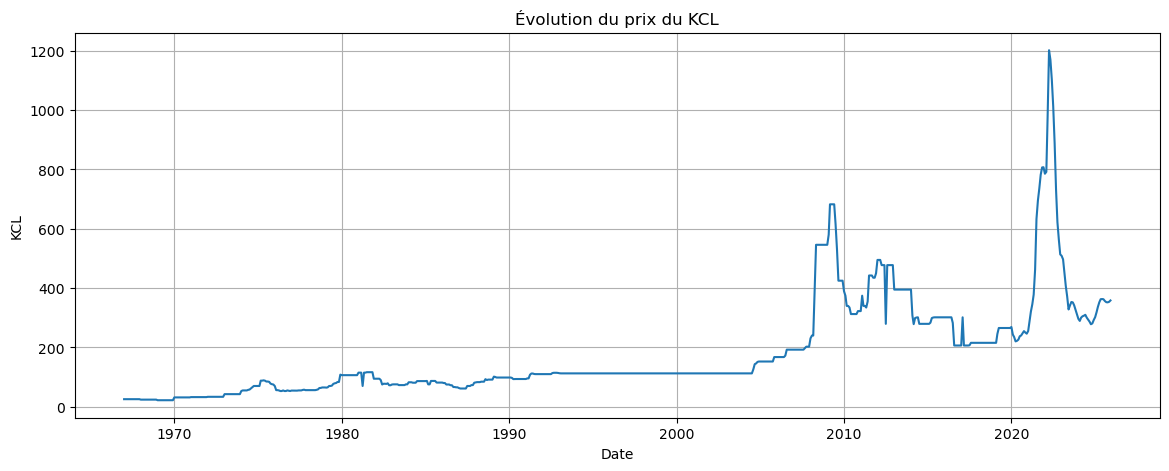

In [119]:
plt.figure(figsize=(14,5))

plt.plot(y)

plt.title("Évolution du prix du KCL")
plt.xlabel("Date")
plt.ylabel("KCL")

plt.grid(True)
plt.show()

In [120]:
result = adfuller(y)

print("ADF Statistic :", result[0])
print("p-value :", result[1])

ADF Statistic : -2.07864399839044
p-value : 0.25318820316219454


In [121]:
if result[1] < 0.05:
    print("La série est stationnaire.")
else:
    print("La série n'est pas stationnaire.")

La série n'est pas stationnaire.


In [123]:
#verifier si une differenciation simple suffit
y_diff = y.diff().dropna()
result_diff = adfuller(y_diff)

print("ADF après différenciation")
print("ADF Statistic :", result_diff[0])
print("p-value :", result_diff[1])
if result_diff[1] < 0.05:
    print("La série différenciée est stationnaire.")
else:
    print("La série différenciée n'est toujours pas stationnaire.")

ADF après différenciation
ADF Statistic : -9.131966979225776
p-value : 3.005163026423488e-15
La série différenciée est stationnaire.


<Figure size 1200x500 with 0 Axes>

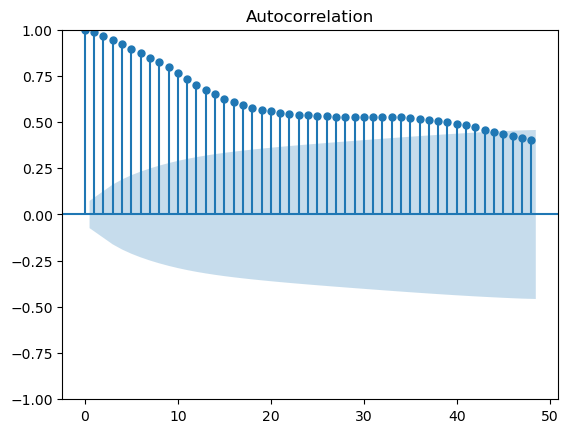

In [125]:
#saisonalite annuelle
s = 12
#acf
plt.figure(figsize=(12,5))

plot_acf(
    y,
    lags=48
)

plt.show()


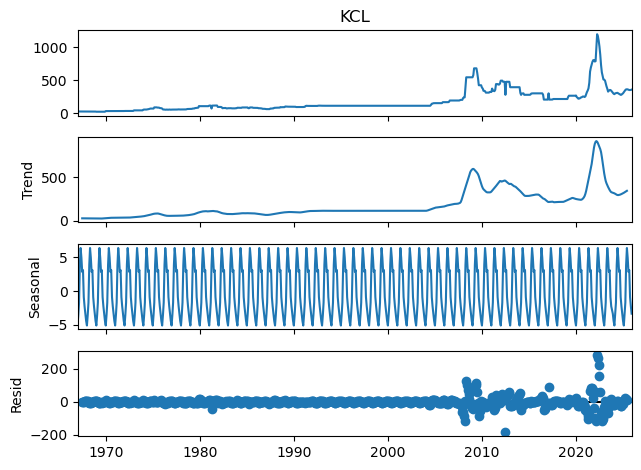

In [126]:
from statsmodels.tsa.seasonal import seasonal_decompose

decomp = seasonal_decompose(
    y,
    model="additive",
    period=12
)

decomp.plot()

plt.show()

In [127]:
corr = df[
    [
        "KCL",
        "Phosphate",
        "DAP",
        "Gas_EUR",
        "Brent"
    ]
].corr()

print(corr["KCL"].sort_values(ascending=False))

KCL          1.000000
Gas_EUR      0.846527
DAP          0.833201
Phosphate    0.813736
Brent        0.798863
Name: KCL, dtype: float64


In [128]:
#train/test split
train_size = int(len(df) * 0.8)

y_train = y.iloc[:train_size]
y_test = y.iloc[train_size:]

X_train = X.iloc[:train_size]
X_test = X.iloc[train_size:]

print("Train :", len(y_train))
print("Test :", len(y_test))

Train : 565
Test : 142


In [129]:
#validation temporelle
validation_size = 12
y_train_sarimax = y_train.iloc[:-validation_size]
y_valid_sarimax = y_train.iloc[-validation_size:]

X_train_sarimax = X_train.iloc[:-validation_size]
X_valid_sarimax = X_train.iloc[-validation_size:]
print("\nTrain validation :", len(y_train_sarimax))
print("Validation        :", len(y_valid_sarimax))


Train validation : 553
Validation        : 12


In [130]:
# Différenciation saisonnière de période 12
y_seasonal_diff = y.diff(12).dropna()

result_seasonal = adfuller(y_seasonal_diff)

print("ADF après différenciation saisonnière :")
print("ADF Statistic :", result_seasonal[0])
print("p-value :", result_seasonal[1])

if result_seasonal[1] < 0.05:
    print("La série est stationnaire après différenciation saisonnière.")
else:
    print("La série n'est pas stationnaire après différenciation saisonnière.")

ADF après différenciation saisonnière :
ADF Statistic : -6.98114215506818
p-value : 8.186281379327542e-10
La série est stationnaire après différenciation saisonnière.


In [ ]:
# #grid search
# warnings.filterwarnings("ignore")


# # #meilleur ordre trouvé avec arima
# # order = (0, 1, 0)

# p = range(0, 3)
# d = [1]
# q = range(0, 3)

# #parametres saisonniers
# P=range(0,2)
# D=[1]
# Q=range(0,2)
# s=12#donnees mensuelles

# results=[]

# count = 1
# total = len(p)*len(d)*len(q)*len(P) * len(D) * len(Q)


# for order in itertools.product(p,d,q):

#      for seasonal in itertools.product(P,D,Q):
#         seasonal_order=(
#             seasonal[0],
#             seasonal[1],
#             seasonal[2],
#             s
#         )

#         print(f"Modèle {count}/{total} : order={order}, seasonal={seasonal_order}")
#         try:
#             model=SARIMAX(
#                 y_train_sarimax,
#                 exog=X_train_sarimax,
#                 order =order,
#                 seasonal_order=seasonal_order,
#                 enforce_stationarity=False,
#                 enforce_invertibility=False

#             )


#             fitted=model.fit(disp=False)

#             #pred de validation
#             forecast_valid = fitted.forecast(
#                 steps=validation_size,
#                 exog=X_valid_sarimax
#             )

#             #metriques de validation


#             mae_valid=mean_absolute_error(
#             y_valid_sarimax,
#             forecast_valid

#             )

#             mse_valid=mean_squared_error(y_valid_sarimax,forecast_valid)

#             rmse_valid=np.sqrt(mse_valid)

#             mape_valid=mean_absolute_percentage_error(y_valid_sarimax,forecast_valid)

#             r2_valid=r2_score(y_valid_sarimax,forecast_valid)


            
            
#             results.append(
#                 {
#                     "Order":order,
#                     "Seasonal_Order":seasonal_order,
#                     "MAE_validation": mae_valid,
#                     "MSE_validation": mse_valid,
#                     "RMSE_validation": rmse_valid,
#                     "MAPE_validation": mape_valid,
#                     "R2_validation": r2_valid,
#                     "AIC":fitted.aic,
#                     "BIC":fitted.bic
#                 }
#             )
#         except Exception as e:
#             print(e)

#         count += 1
# results=pd.DataFrame(results)
# results=results.sort_values(by="RMSE_validation")
# print(results.head(10))

Modèle 1/36 : order=(0, 1, 0), seasonal=(0, 1, 0, 12)
Modèle 2/36 : order=(0, 1, 0), seasonal=(0, 1, 1, 12)
Modèle 3/36 : order=(0, 1, 0), seasonal=(1, 1, 0, 12)
Modèle 4/36 : order=(0, 1, 0), seasonal=(1, 1, 1, 12)
Modèle 5/36 : order=(0, 1, 1), seasonal=(0, 1, 0, 12)
Modèle 6/36 : order=(0, 1, 1), seasonal=(0, 1, 1, 12)
Modèle 7/36 : order=(0, 1, 1), seasonal=(1, 1, 0, 12)
Modèle 8/36 : order=(0, 1, 1), seasonal=(1, 1, 1, 12)
Modèle 9/36 : order=(0, 1, 2), seasonal=(0, 1, 0, 12)
Modèle 10/36 : order=(0, 1, 2), seasonal=(0, 1, 1, 12)
Modèle 11/36 : order=(0, 1, 2), seasonal=(1, 1, 0, 12)
Modèle 12/36 : order=(0, 1, 2), seasonal=(1, 1, 1, 12)
Modèle 13/36 : order=(1, 1, 0), seasonal=(0, 1, 0, 12)
Modèle 14/36 : order=(1, 1, 0), seasonal=(0, 1, 1, 12)
Modèle 15/36 : order=(1, 1, 0), seasonal=(1, 1, 0, 12)
Modèle 16/36 : order=(1, 1, 0), seasonal=(1, 1, 1, 12)
Modèle 17/36 : order=(1, 1, 1), seasonal=(0, 1, 0, 12)
Modèle 18/36 : order=(1, 1, 1), seasonal=(0, 1, 1, 12)
Modèle 19/36 : orde

In [131]:
# ============================================================
# GRID SEARCH SARIMAX - VERSION RAPIDE
# ============================================================

warnings.filterwarnings("ignore")

# Différenciation non saisonnière
d = 1

# Période saisonnière : 12 mois
s = 12

# Petites grilles
p_values = [0, 1, 2]
q_values = [0, 1, 2]

P_values = [0, 1]
Q_values = [0, 1]

# Tester D = 0 et D = 1
D_values = [0, 1]

results = []

count = 1

for p in p_values:
    for q in q_values:

        for P in P_values:
            for D in D_values:
                for Q in Q_values:

                    order = (p, d, q)
                    seasonal_order = (P, D, Q, s)

                    print(
                        f"Modèle {count} : "
                        f"ARIMA{order} "
                        f"SAISONNIER{seasonal_order}"
                    )

                    try:

                        model = SARIMAX(
                            y_train_sarimax,
                            exog=X_train_sarimax,
                            order=order,
                            seasonal_order=seasonal_order,
                            enforce_stationarity=False,
                            enforce_invertibility=False
                        )

                        fitted = model.fit(
                            disp=False,
                            maxiter=200
                        )

                        # Prévision validation
                        forecast_valid = fitted.forecast(
                            steps=validation_size,
                            exog=X_valid_sarimax
                        )

                        # Métriques
                        mae = mean_absolute_error(
                            y_valid_sarimax,
                            forecast_valid
                        )

                        rmse = np.sqrt(
                            mean_squared_error(
                                y_valid_sarimax,
                                forecast_valid
                            )
                        )

                        mape = mean_absolute_percentage_error(
                            y_valid_sarimax,
                            forecast_valid
                        )

                        r2 = r2_score(
                            y_valid_sarimax,
                            forecast_valid
                        )

                        results.append({
                            "Order": order,
                            "Seasonal_Order": seasonal_order,
                            "MAE": mae,
                            "RMSE": rmse,
                            "MAPE": mape,
                            "R2": r2,
                            "AIC": fitted.aic,
                            "BIC": fitted.bic
                        })

                    except Exception as e:

                        print("Erreur :", e)

                    count += 1


# ============================================================
# RESULTATS
# ============================================================

results = pd.DataFrame(results)

results = results.sort_values(
    by="RMSE"
).reset_index(drop=True)

print("\n===== MEILLEURS MODELES =====")

print(
    results[
        [
            "Order",
            "Seasonal_Order",
            "MAE",
            "RMSE",
            "MAPE",
            "R2",
            "AIC"
        ]
    ].head(10)
)

Modèle 1 : ARIMA(0, 1, 0) SAISONNIER(0, 0, 0, 12)
Modèle 2 : ARIMA(0, 1, 0) SAISONNIER(0, 0, 1, 12)
Modèle 3 : ARIMA(0, 1, 0) SAISONNIER(0, 1, 0, 12)
Modèle 4 : ARIMA(0, 1, 0) SAISONNIER(0, 1, 1, 12)
Modèle 5 : ARIMA(0, 1, 0) SAISONNIER(1, 0, 0, 12)
Modèle 6 : ARIMA(0, 1, 0) SAISONNIER(1, 0, 1, 12)
Modèle 7 : ARIMA(0, 1, 0) SAISONNIER(1, 1, 0, 12)
Modèle 8 : ARIMA(0, 1, 0) SAISONNIER(1, 1, 1, 12)
Modèle 9 : ARIMA(0, 1, 1) SAISONNIER(0, 0, 0, 12)
Modèle 10 : ARIMA(0, 1, 1) SAISONNIER(0, 0, 1, 12)
Modèle 11 : ARIMA(0, 1, 1) SAISONNIER(0, 1, 0, 12)
Modèle 12 : ARIMA(0, 1, 1) SAISONNIER(0, 1, 1, 12)
Modèle 13 : ARIMA(0, 1, 1) SAISONNIER(1, 0, 0, 12)
Modèle 14 : ARIMA(0, 1, 1) SAISONNIER(1, 0, 1, 12)
Modèle 15 : ARIMA(0, 1, 1) SAISONNIER(1, 1, 0, 12)
Modèle 16 : ARIMA(0, 1, 1) SAISONNIER(1, 1, 1, 12)
Modèle 17 : ARIMA(0, 1, 2) SAISONNIER(0, 0, 0, 12)
Modèle 18 : ARIMA(0, 1, 2) SAISONNIER(0, 0, 1, 12)
Modèle 19 : ARIMA(0, 1, 2) SAISONNIER(0, 1, 0, 12)
Modèle 20 : ARIMA(0, 1, 2) SAISONNIER(0,

In [83]:
#meilleur modele
best_order=tuple(results.iloc[0]["Order"])
best_seasonal=tuple(results.iloc[0]["Seasonal_Order"])
print("Best order :", best_order)
print("Best seasonal order :", best_seasonal)

Best order : (1, 1, 1)
Best seasonal order : (1, 1, 1, 12)


In [84]:
model = SARIMAX(
    y_train,
    exog=X_train,
    order=best_order,
    seasonal_order=best_seasonal,
    enforce_stationarity=False,
    enforce_invertibility=False
)

In [85]:
model_fit=model.fit(disp=False)
print(model_fit.summary())

                                     SARIMAX Results                                      
Dep. Variable:                                KCL   No. Observations:                  565
Model:             SARIMAX(1, 1, 1)x(1, 1, 1, 12)   Log Likelihood               -2338.084
Date:                            Mon, 10 Aug 2026   AIC                           4694.167
Time:                                    12:30:46   BIC                           4732.758
Sample:                                01-01-1967   HQIC                          4709.262
                                     - 01-01-2014                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Phosphate      0.2606      0.040      6.556      0.000       0.183       0.338
DAP            0.1113      0.022   

In [132]:
#previsions
forecast=model_fit.forecast(
    steps=len(y_test),
    exog=X_test
)

In [134]:
# Aligner les deux séries
y_test_aligned, forecast_aligned = y_test.align(forecast, join="inner")

print(len(y_test_aligned), len(forecast_aligned))

mae = mean_absolute_error(y_test_aligned, forecast_aligned)
mse = mean_squared_error(y_test_aligned, forecast_aligned)
rmse = np.sqrt(mse)
mape = mean_absolute_percentage_error(y_test_aligned, forecast_aligned)
r2 = r2_score(y_test_aligned, forecast_aligned)

print("MAE :", mae)
print("RMSE :", rmse)
print(f"MAPE : {mape*100:.2f}%")
print("R² :", r2)

141 141
MAE : 162.81715204487006
RMSE : 195.7394913294121
MAPE : 49.79%
R² : 0.05864041532636244


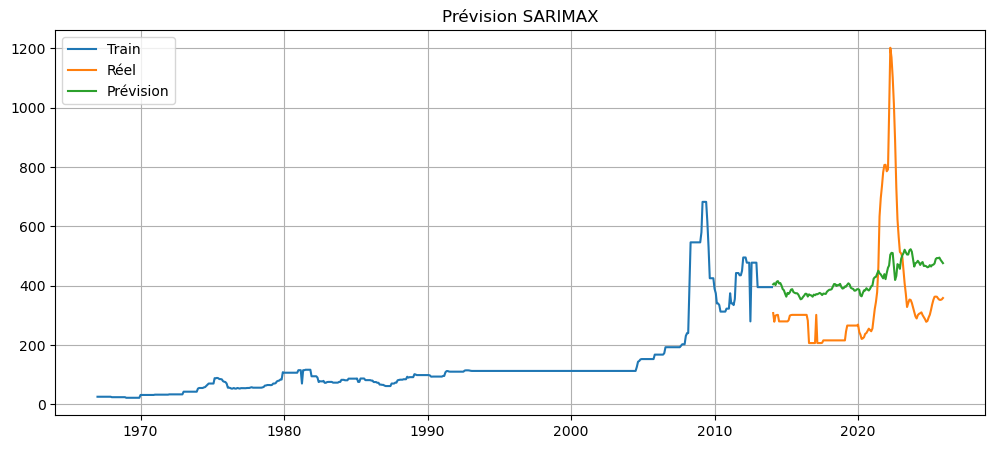

In [135]:
#previsions graphe
plt.figure(figsize=(12,5))

plt.plot(y_train.index, y_train, label="Train")

plt.plot(y_test.index, y_test, label="Réel")

plt.plot(y_test.index, forecast, label="Prévision")

plt.title("Prévision SARIMAX")

plt.legend()

plt.grid(True)

plt.show()

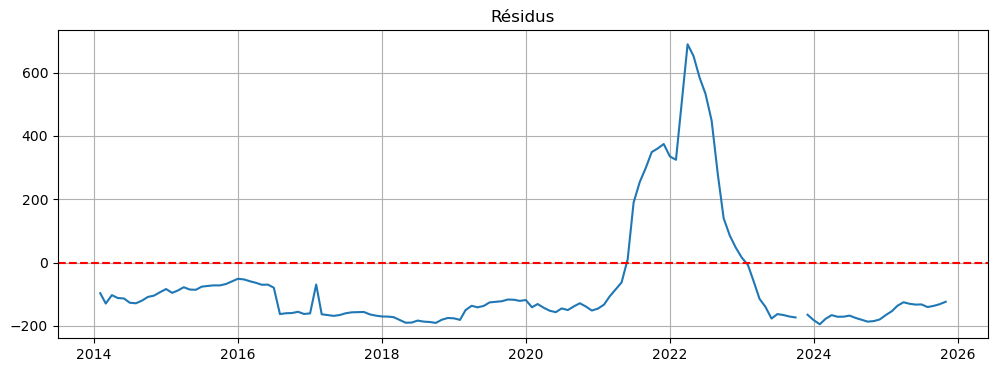

In [43]:
#residus graphe
residuals = y_test - forecast

plt.figure(figsize=(12,4))

plt.plot(residuals)

plt.axhline(0, color="red", linestyle="--")

plt.title("Résidus")

plt.grid(True)

plt.show()

In [44]:
X = df.drop(columns=["KCL"])

In [148]:
train_size = int(len(df) * 0.8)

y_train = y.iloc[:train_size]
y_test = y.iloc[train_size:]

X_train = X.iloc[:train_size]
X_test = X.iloc[train_size:]

In [149]:
# ============================================================
# SARIMAX AVEC VARIABLES HISTORIQUES DE KCL
# ============================================================

warnings.filterwarnings("ignore")

order = (0, 1, 1)
seasonal_order = (0, 1, 1, 12)

print("Order :", order)
print("Seasonal order :", seasonal_order)

model = SARIMAX(
    y_train_sarimax,
    exog=X_train_sarimax,
    order=order,
    seasonal_order=seasonal_order,
    enforce_stationarity=False,
    enforce_invertibility=False
)

model_fit = model.fit(
    disp=False,
    maxiter=200
)

print(model_fit.summary())

Order : (0, 1, 1)
Seasonal order : (0, 1, 1, 12)
                                     SARIMAX Results                                      
Dep. Variable:                                KCL   No. Observations:                  553
Model:             SARIMAX(0, 1, 1)x(0, 1, 1, 12)   Log Likelihood               -2293.422
Date:                            Mon, 10 Aug 2026   AIC                           4600.843
Time:                                    14:01:34   BIC                           4630.700
Sample:                                01-01-1967   HQIC                          4612.534
                                     - 01-01-2013                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Phosphate      0.3208      0.037      8.648      0.000       0.24

In [152]:
results = pd.DataFrame(results)

results = results.sort_values(
    by="RMSE"
).reset_index(drop=True)

print("\n===== MEILLEURS MODELES =====")
print(
    results[
        [
            "Order",
            "Seasonal_Order",
            "MAE",
            "RMSE",
            "MAPE",
            "R2",
            "AIC"
        ]
    ].head(10)
)

best_order = tuple(results.loc[0, "Order"])
best_seasonal = tuple(results.loc[0, "Seasonal_Order"])

print("\nMeilleur modèle :")
print("Order :", best_order)
print("Seasonal Order :", best_seasonal)


===== MEILLEURS MODELES =====
       Order Seasonal_Order        MAE       RMSE      MAPE   R2          AIC
0  (1, 1, 2)  (1, 1, 1, 12)  18.135574  21.018088  0.045913  0.0  4585.093247
1  (1, 1, 1)  (1, 1, 1, 12)  18.245483  21.077035  0.046191  0.0  4590.613824
2  (2, 1, 1)  (1, 1, 1, 12)  18.298022  21.122291  0.046324  0.0  4592.595479
3  (1, 1, 0)  (1, 1, 1, 12)  18.358954  21.241525  0.046478  0.0  4596.979479
4  (0, 1, 1)  (1, 1, 1, 12)  18.380902  21.265069  0.046534  0.0  4588.689914
5  (0, 1, 0)  (1, 1, 1, 12)  18.468006  21.369404  0.046754  0.0  4594.997985
6  (2, 1, 0)  (1, 1, 1, 12)  18.892293  21.710437  0.047829  0.0  4590.412467
7  (0, 1, 2)  (1, 1, 1, 12)  18.933328  21.741292  0.047932  0.0  4582.084118
8  (0, 1, 1)  (0, 1, 1, 12)  21.964971  24.038546  0.055608  0.0  4600.843229
9  (1, 1, 0)  (0, 1, 1, 12)  22.166172  24.231572  0.056117  0.0  4608.733720

Meilleur modèle :
Order : (1, 1, 2)
Seasonal Order : (1, 1, 1, 12)


In [151]:
best_model = SARIMAX(
    y_train,
    exog=X_train,
    order=best_order,
    seasonal_order=best_seasonal,
    enforce_stationarity=False,
    enforce_invertibility=False
)

best_fit = best_model.fit(
    disp=False,
    maxiter=200
)

print(best_fit.summary())

                                      SARIMAX Results                                       
Dep. Variable:                                  KCL   No. Observations:                  556
Model:             SARIMAX(1, 1, 2)x(1, 1, [1], 12)   Log Likelihood               -2260.700
Date:                              Mon, 10 Aug 2026   AIC                           4555.399
Time:                                      14:02:55   BIC                           4627.974
Sample:                                  01-01-1968   HQIC                          4583.811
                                       - 04-01-2014                                         
Covariance Type:                                opg                                         
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
Phosphate            0.2626      0.044      5.992      0.000       0.177       0.349
D

In [153]:
# ============================================================
# VALIDATION
# ============================================================

forecast_valid = model_fit.forecast(
    steps=validation_size,
    exog=X_valid_sarimax
)

mae_valid = mean_absolute_error(
    y_valid_sarimax,
    forecast_valid
)

mse_valid = mean_squared_error(
    y_valid_sarimax,
    forecast_valid
)

rmse_valid = np.sqrt(mse_valid)

mape_valid = mean_absolute_percentage_error(
    y_valid_sarimax,
    forecast_valid
)

r2_valid = r2_score(
    y_valid_sarimax,
    forecast_valid
)

print("\n===== VALIDATION SARIMAX =====")

print("MAE  :", mae_valid)
print("MSE  :", mse_valid)
print("RMSE :", rmse_valid)
print(f"MAPE : {mape_valid * 100:.2f}%")
print("R²   :", r2_valid)


===== VALIDATION SARIMAX =====
MAE  : 21.964970901235898
MSE  : 577.8517008932484
RMSE : 24.038546147661435
MAPE : 5.56%
R²   : 0.0


In [154]:
mae = mean_absolute_error(y_test, forecast)
mse = mean_squared_error(y_test, forecast)
rmse = np.sqrt(mse)
mape = mean_absolute_percentage_error(y_test, forecast)
r2 = r2_score(y_test, forecast)

print("\n===== TEST SARIMAX =====")
print("MAE  :", mae)
print("MSE  :", mse)
print("RMSE :", rmse)
print(f"MAPE : {mape*100:.2f}%")
print("R²   :", r2)

ValueError: Found input variables with inconsistent numbers of samples: [139, 142]